# RT-DETR

Antes de realizar el entrenamiento en colab es necesario hacer la conexión con drive y clonar el repositorio de github de RT-DETR

In [ ]:
#montar Drive
from google.colab import drive

drive.mount('/content/drive')
#extraer los archivos en el disco local del colab
ZIP_PATH = '/content/drive/MyDrive/Datos_P4_split.zip'

!mkdir -p /content/data_raw
!unzip -q "{ZIP_PATH}" -d /content/data_raw

In [ ]:
#clonar repositorio RT-DETR
%cd /content
!git clone https://github.com/lyuwenyu/RT-DETR.git
%cd /content/RT-DETR/rtdetrv2_pytorch

#instalar lo necesario
!pip install -q pycocotools PyYAML scipy tensorboard faster-coco-eval calflops transformers


!mkdir -p /content/weights
!wget -O /content/weights/rtdetrv2_r50vd_m_7x_coco_ema.pth https://github.com/lyuwenyu/storage/releases/download/v0.1/rtdetrv2_r50vd_m_7x_coco_ema.pth



/content
Cloning into 'RT-DETR'...
remote: Enumerating objects: 1272, done.
remote: Counting objects: 100% (93/93), done.
remote: Compressing objects: 100% (55/55), done.
remote: Total 1272 (delta 61), reused 38 (delta 38), pack-reused 1179 (from 2)
Receiving objects: 100% (1272/1272), 875.14 KiB | 16.83 MiB/s, done.
Resolving deltas: 100% (543/543), done.
/content/RT-DETR/rtdetrv2_pytorch
--2026-11-13 17:59:06--  https://github.com/lyuwenyu/storage/releases/download/v0.1/rtdetrv2_r50vd_m_7x_coco_ema.pth
Resolving github.com (github.com)... 20.6.7.17
Connecting to github.com (github.com)|20.6.7.17|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://release-assets.githubusercontent.com/github-production-release-asset/676791659/3d0afe04-d995-408f-898e-b184159826db?sp=r&sv=2018-11-09&sr=b&spr=https&se=2026-11-13T18%3A55%3A41Z&rscd=attachment%3B+filename%3Drtdetrv2_r50vd_m_7x_coco_ema.pth&rsct=application%2Foctet-stream&skoid=96c2d410-5711-43a1-aedd-ab194

Conversión de JSON a formato COCO

In [ ]:
"""
Conversión JSON (YOLO normalizado) -> COCO + YOLO txt, con letterbox opcional.
Genera UN solo dataset de imágenes que usan ambos modelos (mismos píxeles):

OUT/
  train/images/*.jpg   train/labels/*.txt     <- YOLO (Ultralytics)
  val/...              test/...
  annotations/instances_{train,val,test}.json <- COCO (RT-DETR)
"""
import json
from pathlib import Path
from PIL import Image, ImageFile, ImageOps

Image.MAX_IMAGE_PIXELS = None          # permite abrir las imágenes gigantes

ROOT = Path('/content/data_raw/Datos_P4_split')
OUT  = Path('/content/dataset_coco')
IMG_EXT = {'.jpg', '.jpeg', '.png'}

MODE = 'letterbox'     # 'letterbox' (SIZE x SIZE con padding) | 'maxside' (solo reduce)
SIZE = 640
MAX_SIDE = 1920        # para 'maxside'
PAD_COLOR = (114, 114, 114)
JPEG_QUALITY = 95

truncadas = []


def procesar_imagen(src, dst):
    """Guarda la imagen procesada. Devuelve (W, H, w0, h0, s, px, py):
    tamaño final, tamaño original, escala y padding aplicados."""
    ImageFile.LOAD_TRUNCATED_IMAGES = False
    try:
        im = Image.open(src); im.load()
    except OSError:
        truncadas.append(src.name)
        ImageFile.LOAD_TRUNCATED_IMAGES = True
        im = Image.open(src); im.load()
        ImageFile.LOAD_TRUNCATED_IMAGES = False

    im = ImageOps.exif_transpose(im).convert('RGB')
    w0, h0 = im.size

    if MODE == 'letterbox':
        s = min(SIZE / w0, SIZE / h0)
        nw, nh = max(1, round(w0 * s)), max(1, round(h0 * s))
        im = im.resize((nw, nh), Image.LANCZOS)
        canvas = Image.new('RGB', (SIZE, SIZE), PAD_COLOR)
        px, py = (SIZE - nw) // 2, (SIZE - nh) // 2
        canvas.paste(im, (px, py))
        im, W, H = canvas, SIZE, SIZE
    else:
        s = min(1.0, MAX_SIDE / max(w0, h0))
        if s < 1.0:
            im = im.resize((round(w0 * s), round(h0 * s)), Image.LANCZOS)
        px = py = 0
        W, H = im.size

    im.save(dst, quality=JPEG_QUALITY)
    return W, H, w0, h0, s, px, py


def leer_anotaciones(lbl):
    """Devuelve lista de objetos o None si falta / es inválido."""
    if not lbl.exists():
        print(f'Sin JSON de anotaciones, se omite la imagen: {lbl.name}')
        return None
    try:
        with open(lbl) as f:
            return json.load(f)
    except json.JSONDecodeError as e:
        print(f'JSON inválido, se omite la imagen: {lbl.name} ({e})')
        return None


def build_split(name):
    img_src = ROOT / name / 'images'
    ann_src = ROOT / name / 'annotations'
    img_dst = OUT / name / 'images'
    lbl_dst = OUT / name / 'labels'
    (OUT / 'annotations').mkdir(parents=True, exist_ok=True)
    img_dst.mkdir(parents=True, exist_ok=True)
    lbl_dst.mkdir(parents=True, exist_ok=True)

    files = sorted(p for p in img_src.iterdir() if p.suffix.lower() in IMG_EXT)
    coco = {'images': [], 'annotations': [],
            'categories': [{'id': 0, 'name': 'plate'}]}
    img_id, ann_id = 0, 1
    omitidas = vacias = 0

    for p in files:
        objs = leer_anotaciones(ann_src / (p.stem + '.json'))
        if objs is None:                 # no se incluye ni se copia la imagen
            omitidas += 1
            continue

        img_id += 1
        out_name = p.stem + '.jpg'
        W, H, w0, h0, s, px, py = procesar_imagen(p, img_dst / out_name)
        coco['images'].append({'id': img_id, 'file_name': out_name,
                               'width': W, 'height': H})
        yolo_lines = []

        for obj in objs:
            xc, yc, w, h = obj['rectangle']          # normalizado sobre la ORIGINAL
            x1, y1 = max(0, (xc - w / 2) * w0), max(0, (yc - h / 2) * h0)
            x2, y2 = min(w0, (xc + w / 2) * w0), min(h0, (yc + h / 2) * h0)
            # a coordenadas de la imagen final (escala + padding)
            x1, x2 = x1 * s + px, x2 * s + px
            y1, y2 = y1 * s + py, y2 * s + py
            bw, bh = x2 - x1, y2 - y1
            if bw <= 1 or bh <= 1:
                continue
            coco['annotations'].append({
                'id': ann_id, 'image_id': img_id, 'category_id': 0,
                'bbox': [round(x1, 2), round(y1, 2), round(bw, 2), round(bh, 2)],
                'area': round(bw * bh, 2), 'iscrowd': 0})
            ann_id += 1
            yolo_lines.append(f'0 {(x1 + bw / 2) / W:.6f} {(y1 + bh / 2) / H:.6f} '
                              f'{bw / W:.6f} {bh / H:.6f}')

        if not yolo_lines:
            vacias += 1
        (lbl_dst / (p.stem + '.txt')).write_text('\n'.join(yolo_lines))

    with open(OUT / 'annotations' / f'instances_{name}.json', 'w') as f:
        json.dump(coco, f)
    print(f'{name}: {len(coco["images"])} imágenes, {len(coco["annotations"])} cajas, '
          f'{omitidas} omitidas (sin/!JSON), {vacias} sin ninguna caja')


if __name__ == '__main__':
    for s in ['train', 'val', 'test']:
        build_split(s)
    print(len(truncadas), 'imágenes truncadas')
    for n in truncadas:
        print(n)

JSON inválido, se omite la imagen: matricula14.json (Expecting ',' delimiter: line 5 column 7 (char 57))
JSON inválido, se omite la imagen: matricula15.json (Expecting ',' delimiter: line 5 column 6 (char 55))
JSON inválido, se omite la imagen: matricula16.json (Expecting ',' delimiter: line 5 column 7 (char 57))
JSON inválido, se omite la imagen: matricula2.json (Expecting ',' delimiter: line 5 column 7 (char 58))
train: 1543 imágenes, 3271 cajas, 4 omitidas (sin/!JSON), 0 sin ninguna caja
JSON inválido, se omite la imagen: matricula1.json (Expecting ',' delimiter: line 5 column 7 (char 57))
JSON inválido, se omite la imagen: matricula12.json (Expecting ',' delimiter: line 5 column 7 (char 56))
JSON inválido, se omite la imagen: matricula4.json (Expecting ',' delimiter: line 5 column 8 (char 60))
JSON inválido, se omite la imagen: matricula7.json (Expecting ',' delimiter: line 5 column 7 (char 57))
val: 383 imágenes, 825 cajas, 4 omitidas (sin/!JSON), 1 sin ninguna caja
JSON inválido,

In [ ]:
#Entrenamiento con modelo M

!python tools/train.py -c configs/rtdetrv2/rtdetrv2_r50vd_m_100e_plates.yml -t /content/weights/rtdetrv2_r50vd_m_7x_coco_ema.pth --use-amp --seed=0

I0000 00:00:1794564751.262557   10743 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1794564753.507598   10743 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
Not init distributed mode.
cfg:  {'task': 'detection', '_model': None, '_postprocessor': None, '_criterion': None, '_optimizer': None, '_lr_scheduler': None, '_lr_warmup_scheduler': None, '_train_dataloader': None, '_val_dataloader': None, '_ema': None, '_scaler': None, '_train_dataset': None, '_val_dataset': None, '_collate_fn': None, '_evaluator': None, '_writer': None, 'num_workers': 0, 'batch_size': None, '_train_batch_size': None, '_val_batch_size': None, '_train_shuffle': None, '_val_shuffle': None, 'resume': None, 'tuning': '/content/weights/rtdetrv2_r50vd_m_7

Comando para entrenar a partir de un checkpoint

In [ ]:
!python tools/train.py -c configs/rtdetrv2/rtdetrv2_r50vd_m_100e_plates.yml \
  -r /content/drive/MyDrive/matriculas/output/rtdetrv2_r34vd_100e_plates/last.pth --use-amp --seed=0

I0000 00:00:1794593480.836701    5203 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1794593485.634082    5203 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
/content/RT-DETR/rtdetrv2_pytorch/tools/../src/misc/profiler_utils.py:58: SyntaxWarning: invalid escape sequence '\d'
  num_flops = sum([float(v.strip()) for v in re.findall('(\d+.?\d+ *\n)', info)]) / num_active
Not init distributed mode.
cfg:  {'task': 'detection', '_model': None, '_postprocessor': None, '_criterion': None, '_optimizer': None, '_lr_scheduler': None, '_lr_warmup_scheduler': None, '_train_dataloader': None, '_val_dataloader': None, '_ema': None, '_scaler': None, '_train_dataset': None, '_val_dataset': None, '_collate_fn': None, '_evaluator': None, '_

Código para la obtención de gráficas a partir de log.txt

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
100 épocas registradas


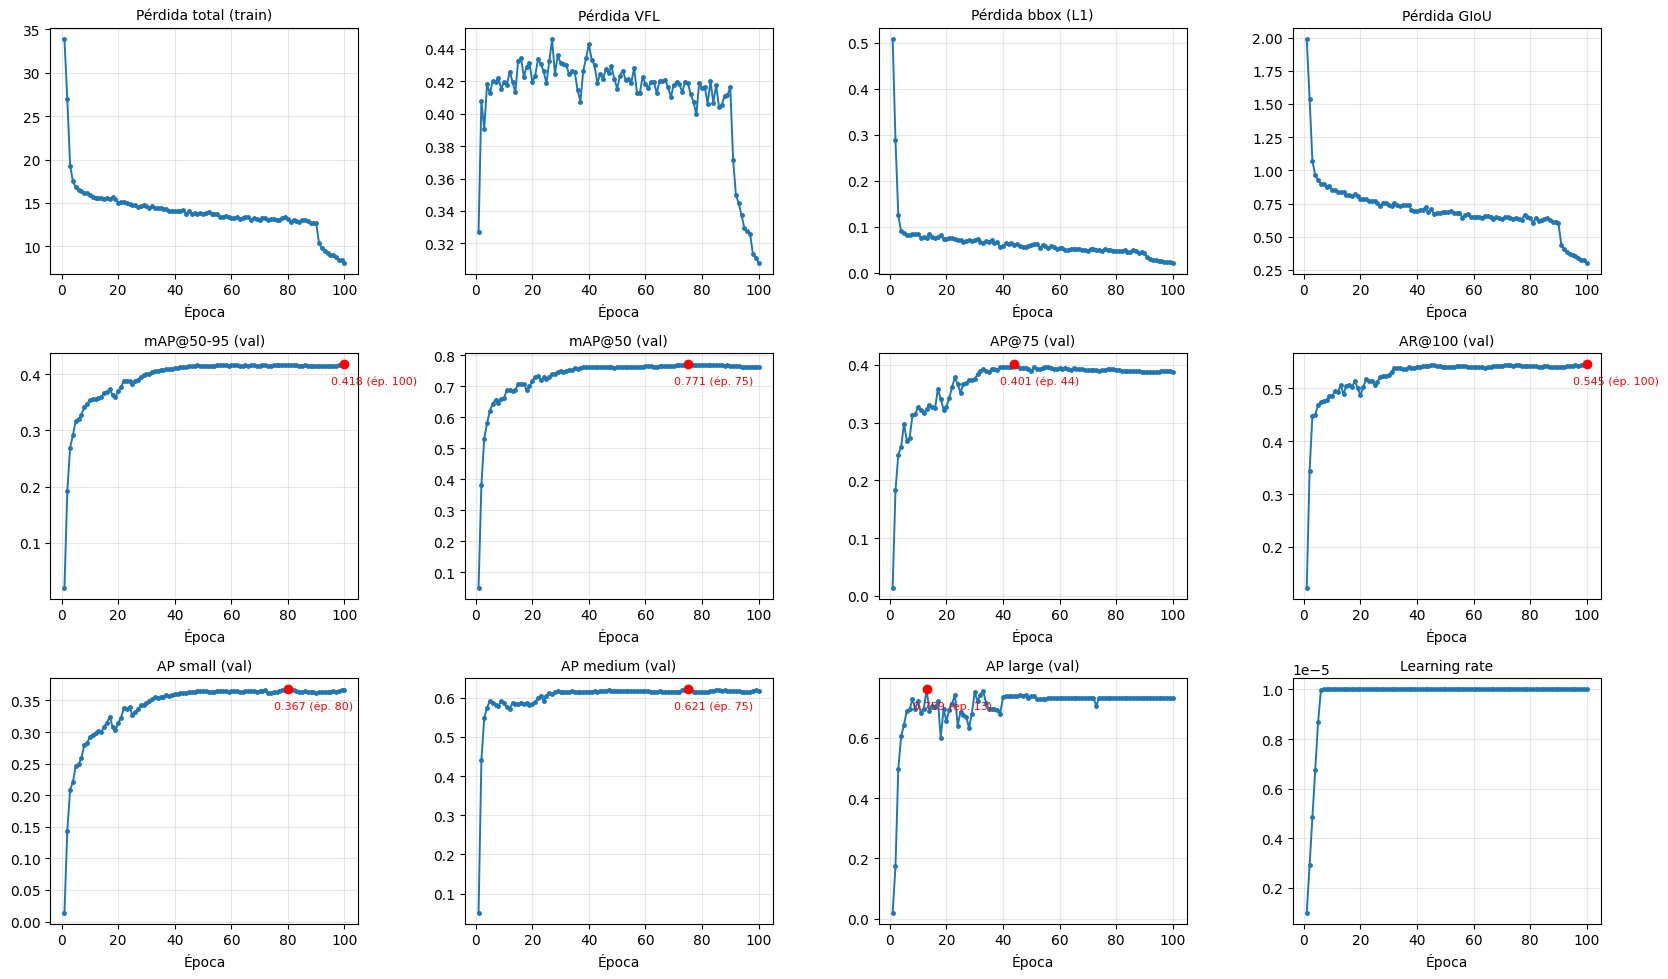

Guardado en /content/drive/MyDrive/matriculas/graficas// (results.png + una imagen por curva)


In [ ]:
import json, os
import matplotlib.pyplot as plt

LOG = '/content/drive/MyDrive/matriculas/output/rtdetrv2_r34vd_100e_plates/log.txt'
OUT = '/content/drive/MyDrive/matriculas/graficas/'
os.makedirs(OUT, exist_ok=True)

# (clave, título, índice en test_coco_eval_bbox)
# [AP, AP50, AP75, APs, APm, APl, AR1, AR10, AR100, ARs, ARm, ARl]
CURVAS = [
    ('train_loss', 'Pérdida total (train)', None), ('train_loss_vfl', 'Pérdida VFL', None),
    ('train_loss_bbox', 'Pérdida bbox (L1)', None), ('train_loss_giou', 'Pérdida GIoU', None),
    ('ap', 'mAP@50-95 (val)', 0), ('ap50', 'mAP@50 (val)', 1),
    ('ap75', 'AP@75 (val)', 2), ('ar100', 'AR@100 (val)', 8),
    ('ap_small', 'AP small (val)', 3), ('ap_medium', 'AP medium (val)', 4),
    ('ap_large', 'AP large (val)', 5), ('train_lr', 'Learning rate', None),
]

rows = [json.loads(l) for l in open(LOG) if l.strip()]
print(f'{len(rows)} épocas registradas')

def serie(clave, idx):
    xs, ys = [], []
    for r in rows:
        v = (r['test_coco_eval_bbox'][idx] if r.get('test_coco_eval_bbox') else None) \
            if idx is not None else r.get(clave)
        if v is not None:
            xs.append(r['epoch'] + 1); ys.append(v)   # RT-DETR cuenta desde 0
    return xs, ys

def dibujar(ax, xs, ys, titulo, marcar_mejor):
    ax.plot(xs, ys, marker='o', ms=2.5, lw=1.4)
    if marcar_mejor:
        i = max(range(len(ys)), key=ys.__getitem__)
        ax.scatter([xs[i]], [ys[i]], color='red', zorder=3)
        ax.annotate(f'{ys[i]:.3f} (ép. {xs[i]})', (xs[i], ys[i]),
                    textcoords='offset points', xytext=(-10, -14), fontsize=8, color='red')
    ax.set_title(titulo, fontsize=10); ax.set_xlabel('Época'); ax.grid(alpha=.3)

datos = [(c, t) + serie(c, i) for c, t, i in CURVAS]
datos = [d for d in datos if d[2]]                     # descarta curvas sin datos

# Imágenes individuales
for clave, titulo, xs, ys in datos:
    fig, ax = plt.subplots(figsize=(6, 4))
    dibujar(ax, xs, ys, titulo, not clave.startswith('train'))
    fig.tight_layout(); fig.savefig(f'{OUT}/{clave}.png', dpi=150); plt.close(fig)

# Panel conjunto (se muestra en la celda y se guarda como results.png)
cols = 4
filas = -(-len(datos) // cols)
fig, axes = plt.subplots(filas, cols, figsize=(4.2 * cols, 3.3 * filas))
axes = axes.flatten()
for ax, (clave, titulo, xs, ys) in zip(axes, datos):
    dibujar(ax, xs, ys, titulo, not clave.startswith('train'))
for ax in axes[len(datos):]:
    ax.axis('off')
fig.tight_layout(); fig.savefig(f'{OUT}/results.png', dpi=150)
plt.show()
print(f'Guardado en {OUT}/ (results.png + una imagen por curva)')



Contenidos de los dos archivos de configuración necesarios para en entrenamiento del modelo



In [ ]:
# Copiar a rtdetrv2_pytorch/configs/rtdetrv2/
# RT-DETRv2-M (r50vd_m): hereda la arquitectura de la config OFICIAL y solo cambia
# dataset, épocas, warmup/EMA y aumentos. Verifica que existe con: ls configs/rtdetrv2/
__include__: [
  './rtdetrv2_r50vd_m_7x_coco.yml',
  '../dataset/plates_detection.yml',
]

output_dir: /content/drive/MyDrive/matriculas/output/rtdetrv2_r34vd_100e_plates

# Checkpoint COCO de RT-DETRv2-M (se puede pasar también con -t)
tuning: /content/weights/rtdetrv2_r50vd_m_7x_coco_ema.pth

epoches: 100
checkpoint_freq: 10
print_freq: 20
clip_max_norm: 0.1
use_amp: True
use_ema: True

# Warmup y EMA reducidos: solo hay ~9000 iteraciones en total
lr_warmup_scheduler:
  type: LinearWarmup
  warmup_duration: 500

ema:
  type: ModelEMA
  decay: 0.9999
  warmups: 500

train_dataloader:
  total_batch_size: 16
  num_workers: 2
  dataset:
    transforms:
      type: Compose
      ops:
        - {type: RandomPhotometricDistort, p: 0.5}
        - {type: RandomZoomOut, fill: 0}
        - {type: RandomIoUCrop, p: 0.8}
        - {type: SanitizeBoundingBoxes, min_size: 1}
        - {type: Resize, size: [640, 640]}
        - {type: SanitizeBoundingBoxes, min_size: 1}
        - {type: ConvertPILImage, dtype: 'float32', scale: True}
        - {type: ConvertBoxes, fmt: 'cxcywh', normalize: True}
      policy:
        name: stop_epoch
        epoch: 90          # últimas 10 épocas sin aumentos fuertes (como close_mosaic en YOLO)
        ops: ['RandomPhotometricDistort', 'RandomZoomOut', 'RandomIoUCrop']
  collate_fn:
    scales: [480, 512, 544, 576, 608, 640, 640, 640]
    stop_epoch: 90

val_dataloader:
  total_batch_size: 16
  num_workers: 2

eval_spatial_size: [640, 640]

In [ ]:
# Dataset de matrículas (formato COCO). Copiar a rtdetrv2_pytorch/configs/dataset/
# Solo define clases y rutas; los aumentos y el collate_fn vienen de la config oficial.
task: detection

evaluator:
  type: CocoEvaluator
  iou_types: ['bbox', ]

num_classes: 1                 # category id = 0 en el JSON COCO
remap_mscoco_category: False   # imprescindible con dataset propio

train_dataloader:
  dataset:
    img_folder: /content/dataset_coco/train/images
    ann_file: /content/dataset_coco/annotations/instances_train.json

val_dataloader:
  dataset:
    img_folder: /content/dataset_coco/val/images
    ann_file: /content/dataset_coco/annotations/instances_val.json

-----------------------------------------------------------------------------------------